# Forecasting Daerah Tertinggal by Island

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pickle
import math
from sklearn.linear_model import LinearRegression

# Load Data Utama
df = pd.read_csv('../data/clean_water.csv')

# Tambahkan kolom provinsi dan pulau
dict_provinsi = {
    'AC': 'Aceh', 'BA': 'Bali', 'BB': 'Kep. Bangka Belitung', 'BE': 'Bengkulu', 
    'BT': 'Banten', 'GO': 'Gorontalo', 'IB': 'Papua Barat', 'JA': 'Jambi',
    'JI': 'Jawa Timur', 'JR': 'Jawa Barat', 'JT': 'Jawa Tengah', 'KB': 'Kalimantan Barat',
    'KI': 'Kalimantan Timur', 'KR': 'Kep. Riau', 'KS': 'Kalimantan Selatan', 
    'KT': 'Kalimantan Tengah', 'KU': 'Kalimantan Utara', 'LA': 'Lampung', 'MA': 'Maluku', 
    'MU': 'Maluku Utara', 'NB': 'Nusa Tenggara Barat', 'NT': 'Nusa Tenggara Timur', 
    'PA': 'Papua', 'RI': 'Riau', 'SB': 'Sumatera Barat', 'SE': 'Sulawesi Selatan', 
    'SG': 'Sulawesi Tenggara', 'SL': 'Sumatera Selatan', 'SR': 'Sulawesi Barat', 
    'ST': 'Sulawesi Tengah', 'SU': 'Sumatera Utara', 'SW': 'Sulawesi Utara', 'YO': 'DI Yogyakarta'
}

dict_pulau = {
    'Aceh': 'Sumatera', 'Sumatera Utara': 'Sumatera', 'Sumatera Barat': 'Sumatera',
    'Riau': 'Sumatera', 'Kep. Riau': 'Sumatera', 'Jambi': 'Sumatera',
    'Sumatera Selatan': 'Sumatera', 'Bengkulu': 'Sumatera', 'Lampung': 'Sumatera',
    'Kep. Bangka Belitung': 'Sumatera', 'Banten': 'Jawa', 'Jawa Barat': 'Jawa',
    'Jawa Tengah': 'Jawa', 'DI Yogyakarta': 'Jawa', 'Jawa Timur': 'Jawa',
    'Bali': 'Bali & Nusa Tenggara', 'Nusa Tenggara Barat': 'Bali & Nusa Tenggara',
    'Nusa Tenggara Timur': 'Bali & Nusa Tenggara', 'Kalimantan Barat': 'Kalimantan',
    'Kalimantan Tengah': 'Kalimantan', 'Kalimantan Selatan': 'Kalimantan',
    'Kalimantan Timur': 'Kalimantan', 'Kalimantan Utara': 'Kalimantan',
    'Sulawesi Utara': 'Sulawesi', 'Gorontalo': 'Sulawesi', 'Sulawesi Tengah': 'Sulawesi',
    'Sulawesi Barat': 'Sulawesi', 'Sulawesi Selatan': 'Sulawesi', 'Sulawesi Tenggara': 'Sulawesi',
    'Maluku': 'Maluku & Papua', 'Maluku Utara': 'Maluku & Papua',
    'Papua': 'Maluku & Papua', 'Papua Barat': 'Maluku & Papua'
}

df['kode_prov'] = df['id'].astype(str).apply(lambda x: x.split('.')[1] if '.' in x else x)
df['provinsi'] = df['kode_prov'].map(dict_provinsi)
df['pulau'] = df['provinsi'].map(dict_pulau)

# Load Hasil Clustering (K-Means) untuk mendapatkan daerah Solid 1 (Cluster 0)
df_cluster = pd.read_csv('Hasil_KMeans_AksesAir.csv')
solid1_daerah = df_cluster[df_cluster['Cluster_KMeans'] == 0]['daerah'].tolist()

print(f"Total Daerah Tertinggal (Solid 1): {len(solid1_daerah)}")

# Load Model XGBoost yang sudah dilatih
with open('Model_AirBersih_.pkl', 'rb') as file:
    model_forecast = pickle.load(file)
    
# FIX: OneHotEncoder drop='first' on 'year' causes error for future years.
model_forecast.named_steps['preprocessing'].transformers_[0][1].handle_unknown = 'ignore'


Total Daerah Tertinggal (Solid 1): 33


In [2]:
def project_feature(df_daerah, feature, years_future):
    X = df_daerah['year'].values.reshape(-1, 1)
    y = df_daerah[feature].values
    reg = LinearRegression().fit(X, y)
    return reg.predict(np.array(years_future).reshape(-1, 1))

forecast_years = [2025, 2030, 2040, 2045]
all_forecasts = []

for daerah in solid1_daerah:
    df_d = df[df['daerah'] == daerah].sort_values('year')
    if df_d.empty: continue
    
    # Ambil data tahun 2020 sebagai base
    df_2020_rows = df_d[df_d['year'] == 2020]
    if df_2020_rows.empty:
        last_row = df_d.iloc[-1]
    else:
        last_row = df_2020_rows.iloc[0]

    for yr in forecast_years:
        row = {
            'year': yr,
            'daerah': daerah,
            'tingkat': last_row['tingkat'],
            'status': last_row['status'],
            'logpop': project_feature(df_d, 'logpop', [yr])[0],
            'logarea': float(last_row['logarea']),
            'logpad': project_feature(df_d, 'logpad', [yr])[0],
            'morbid': project_feature(df_d, 'morbid', [yr])[0],
        }
        all_forecasts.append(row)

df_forecast = pd.DataFrame(all_forecasts)

# Lakukan prediksi menggunakan model .pkl
features_order = ['logpop', 'logarea', 'logpad', 'year', 'morbid', 'daerah', 'tingkat', 'status']
df_forecast['water'] = model_forecast.predict(df_forecast[features_order])
# Batasi nilai persentase di rentang [0, 100]
df_forecast['water'] = df_forecast['water'].clip(0, 100)


/Users/yudhapratama/Documents/Science/Publikasi/clean-water-access/.venv/lib/python3.14/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


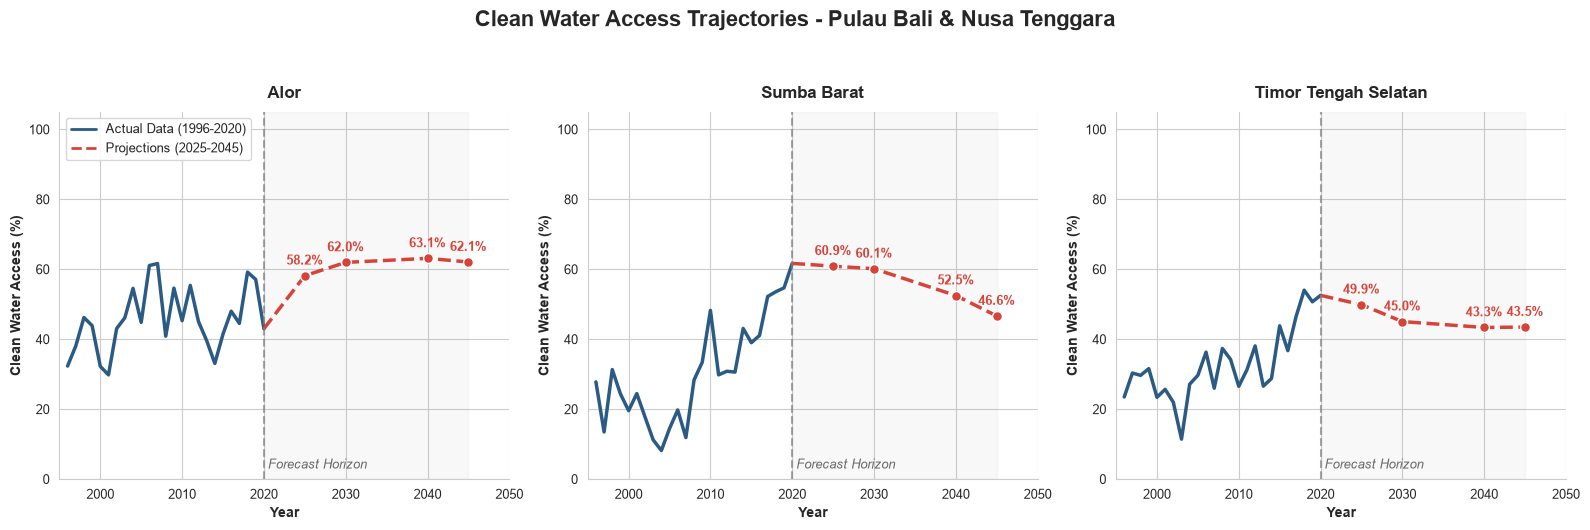

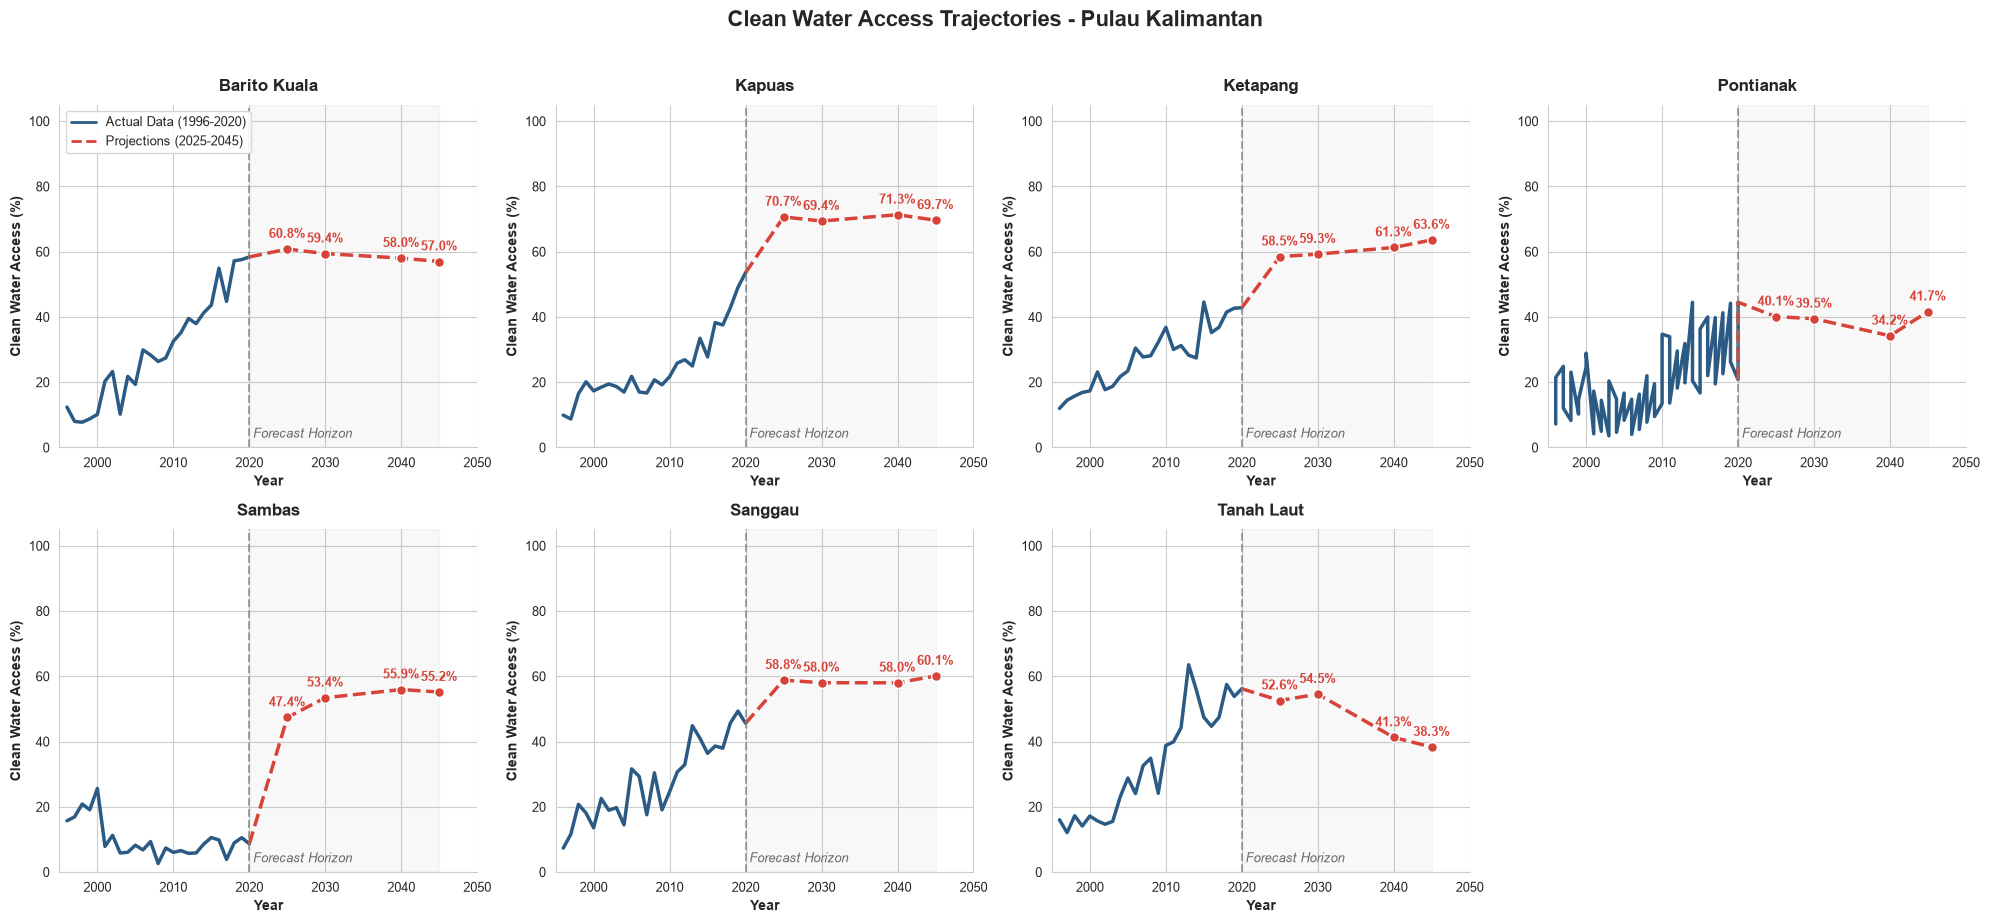

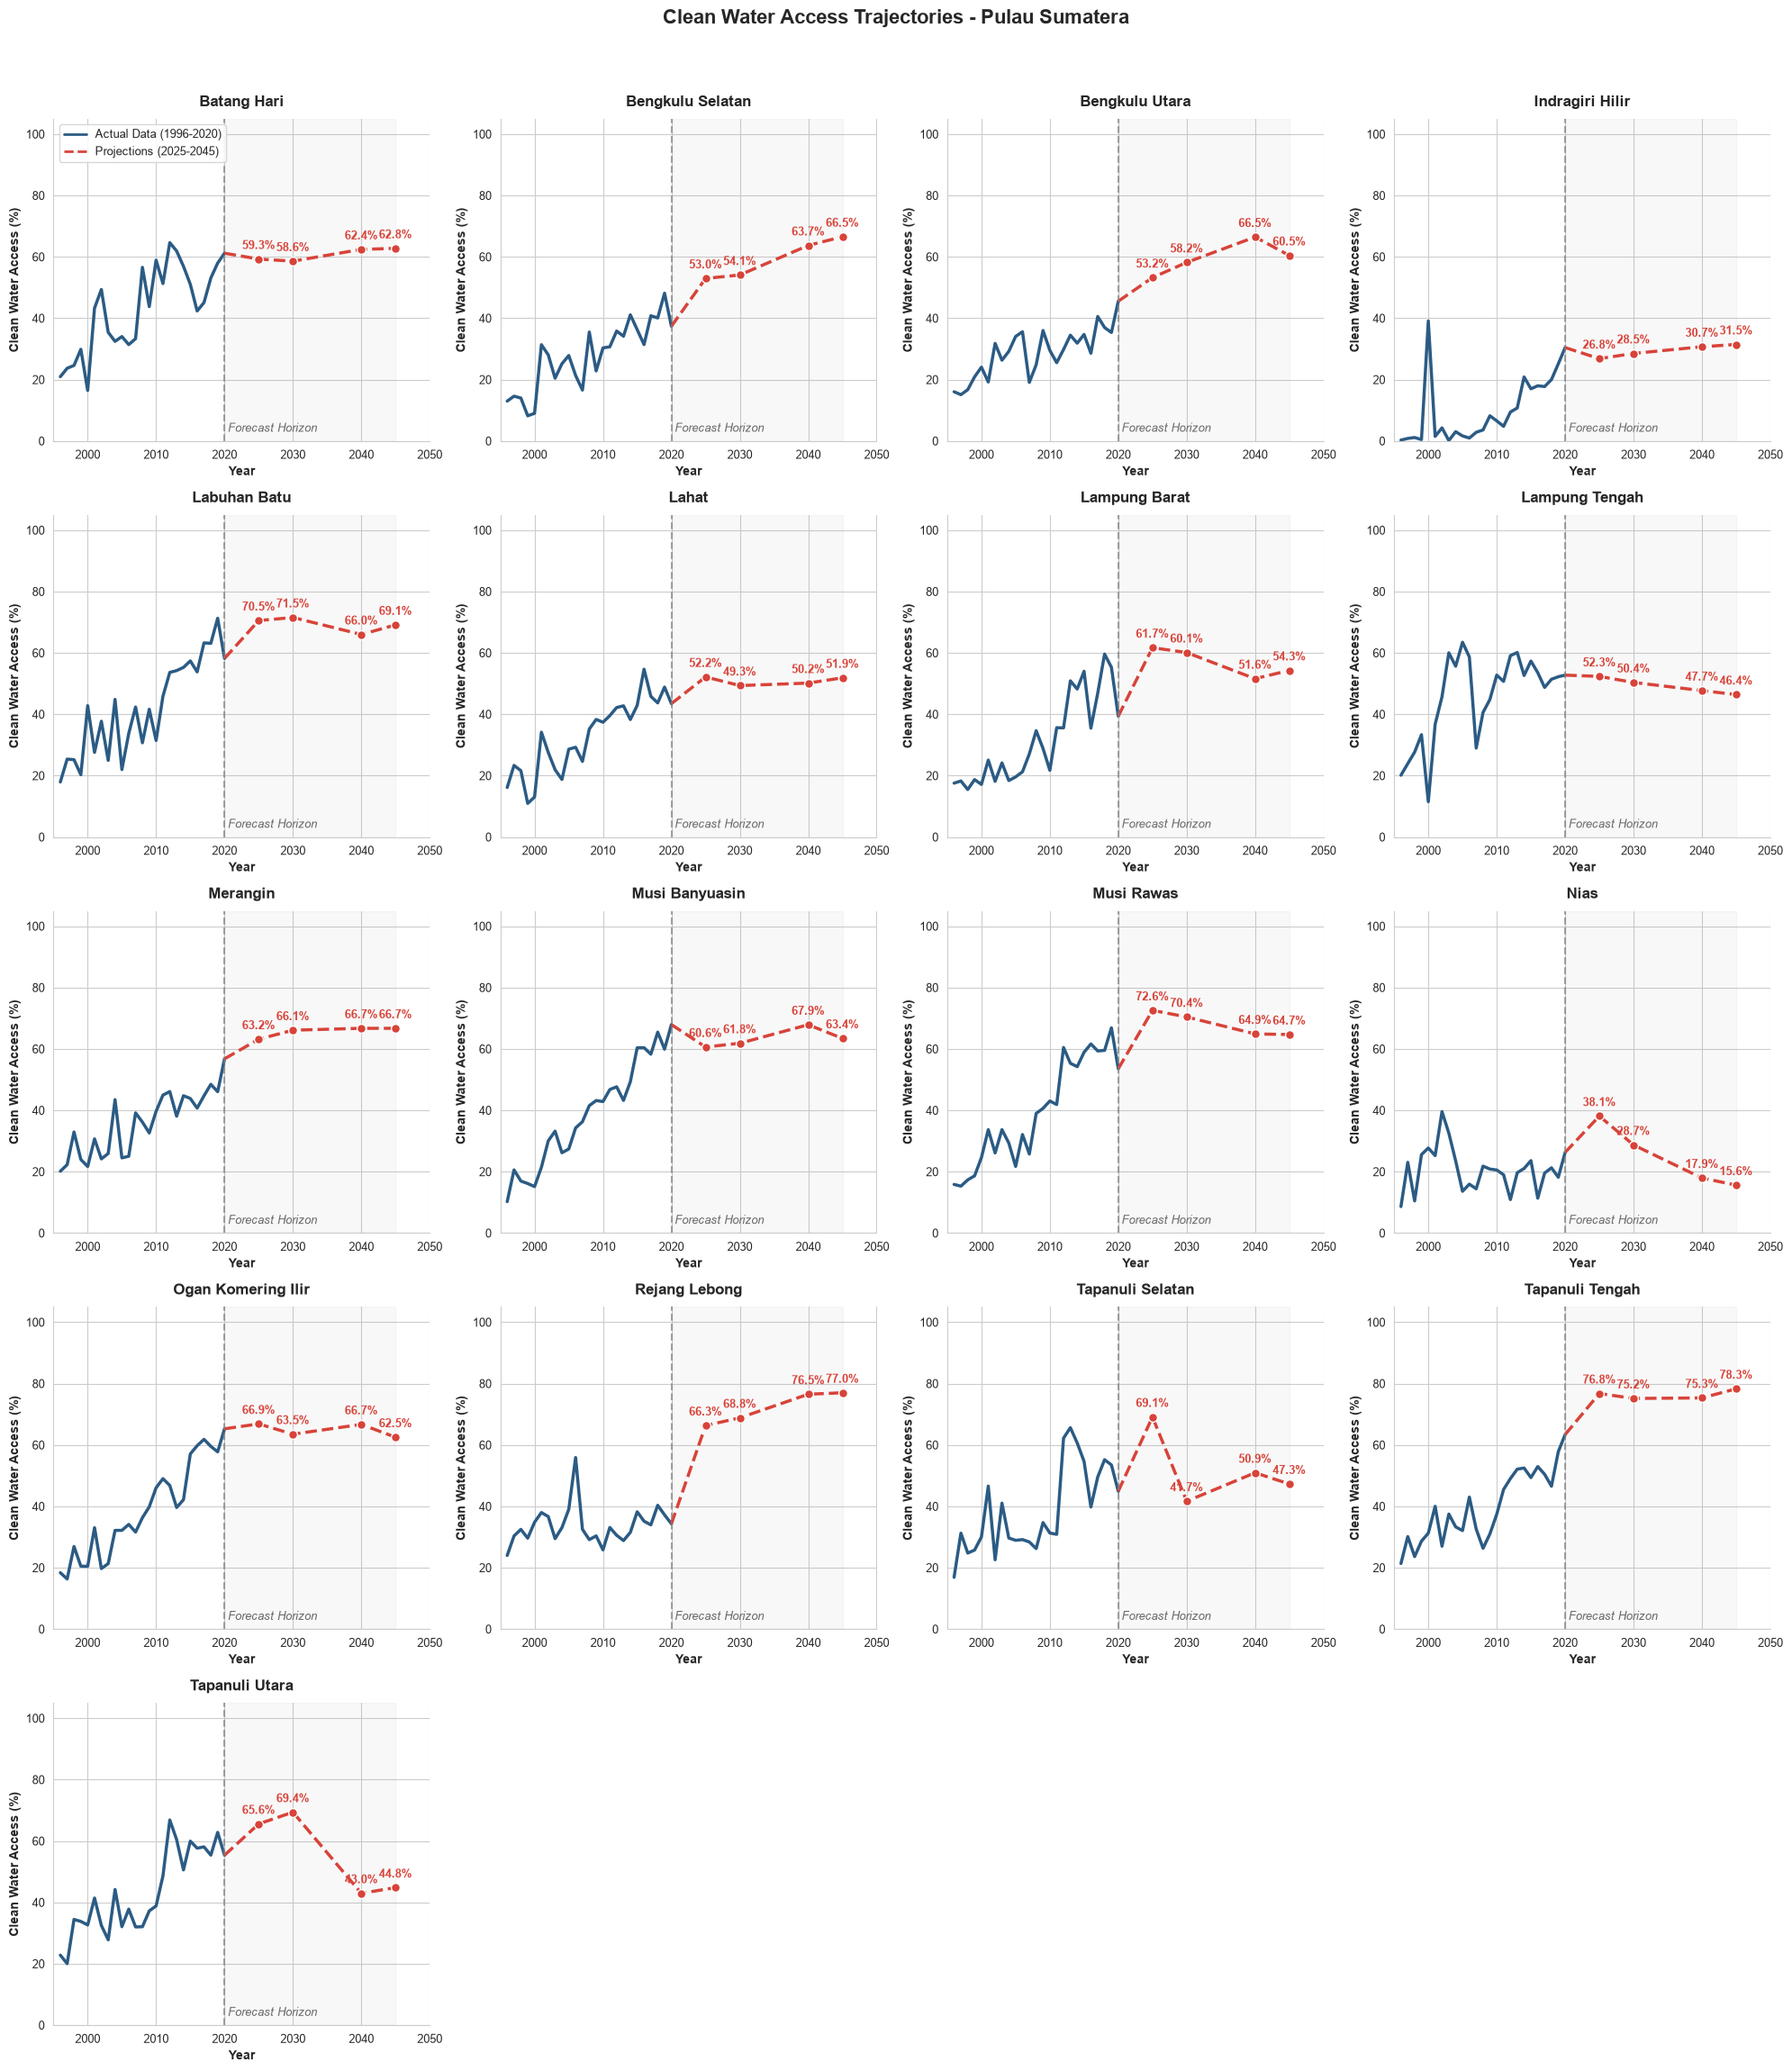

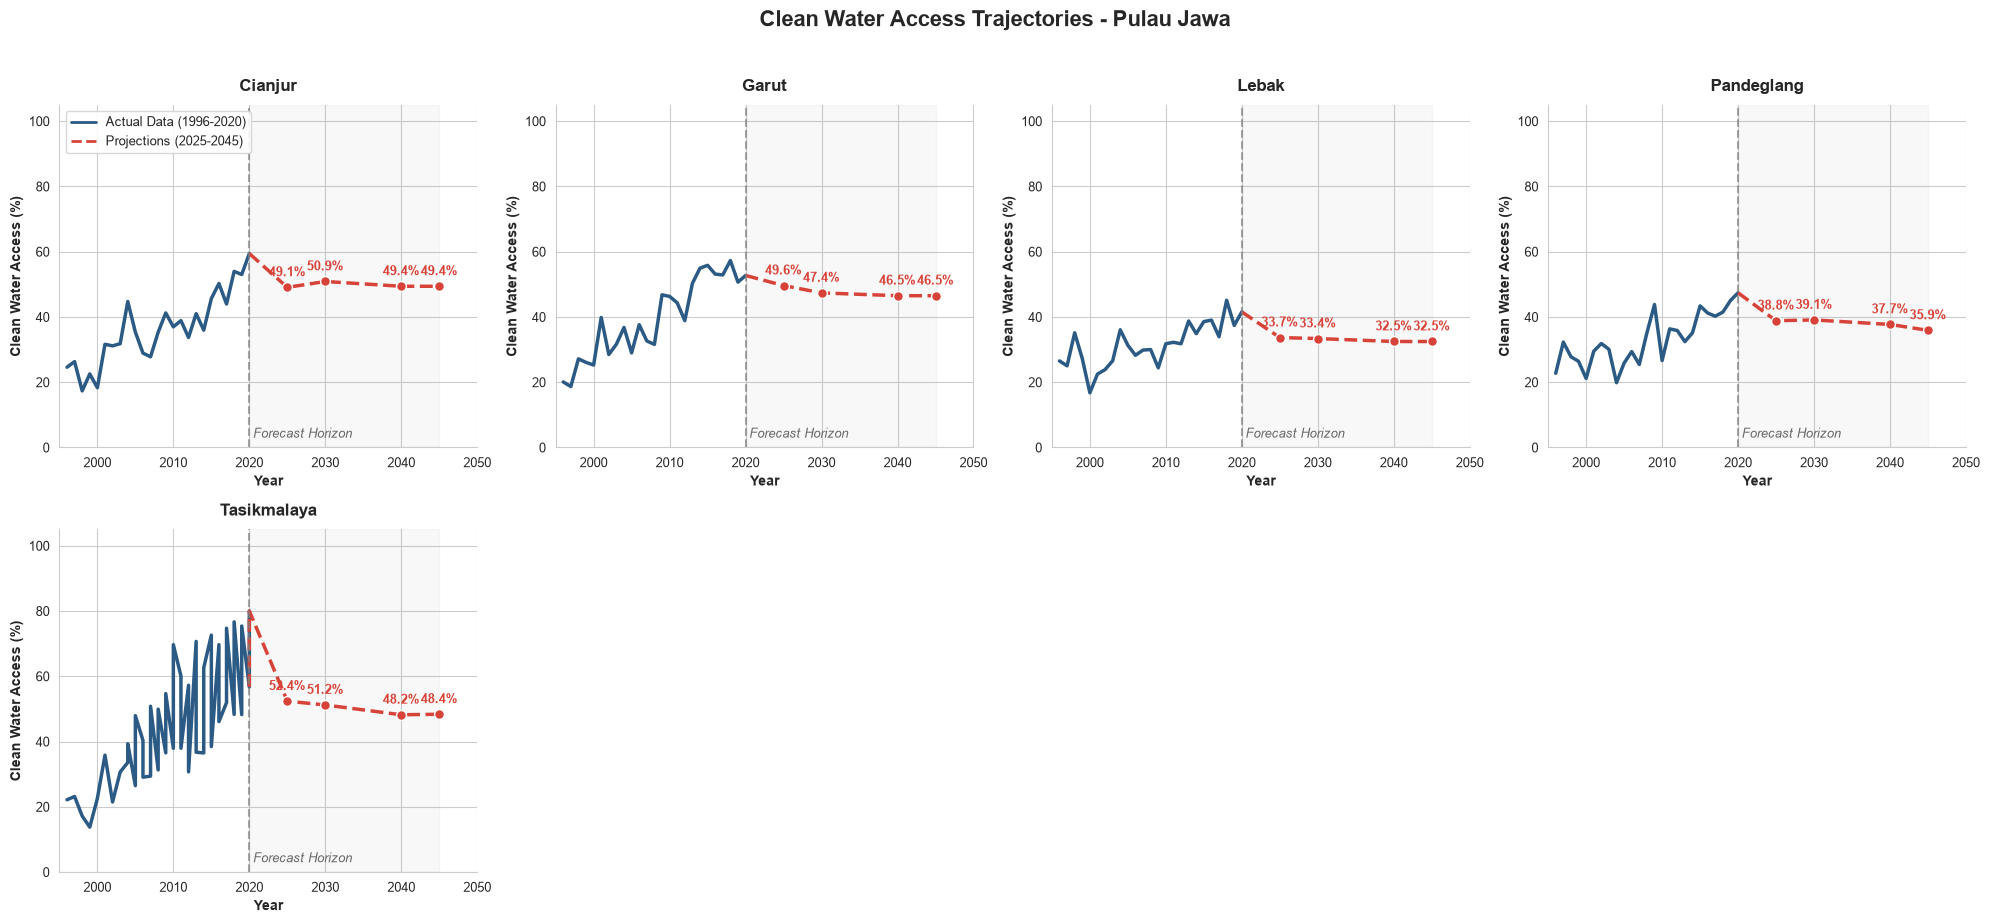

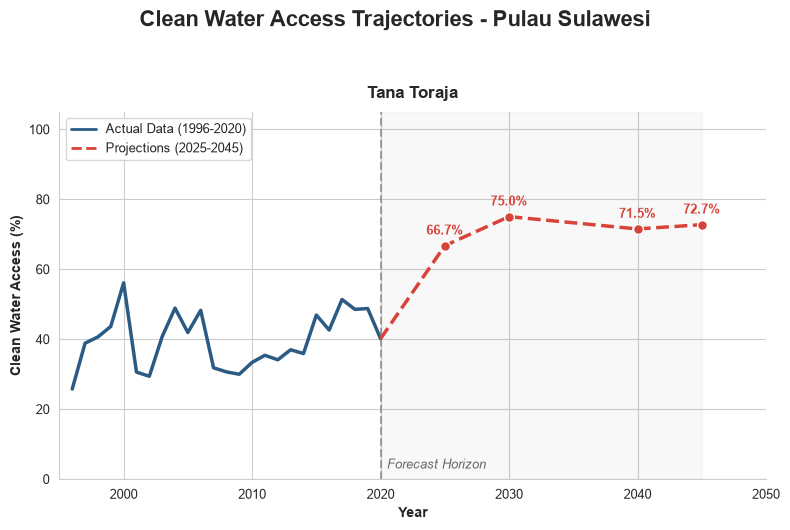

In [3]:

# Kelompokkan daerah berdasarkan pulau
pulau_daerah = {}
for daerah in solid1_daerah:
    pulaus = df[df['daerah'] == daerah]['pulau'].dropna().unique()
    pul = pulaus[0] if len(pulaus) > 0 else 'Unknown'
    if pul not in pulau_daerah:
        pulau_daerah[pul] = []
    pulau_daerah[pul].append(daerah)


# Kelompokkan daerah berdasarkan pulau
pulau_daerah = {}
for daerah in solid1_daerah:
    pulaus = df[df['daerah'] == daerah]['pulau'].dropna().unique()
    pul = pulaus[0] if len(pulaus) > 0 else 'Unknown'
    if pul not in pulau_daerah:
        pulau_daerah[pul] = []
    pulau_daerah[pul].append(daerah)

# Visualisasi per pulau (Q1 Grade)
import seaborn as sns
sns.set_style("whitegrid")

for pul, daerah_list in pulau_daerah.items():
    n_plots = len(daerah_list)
    
    # Dynamic grid layout for centering
    if n_plots == 1:
        ncols, nrows = 1, 1
        figsize = (8, 5)
    elif n_plots == 2:
        ncols, nrows = 2, 1
        figsize = (12, 5)
    elif n_plots == 3:
        ncols, nrows = 3, 1
        figsize = (16, 5)
    else:
        ncols = 4
        nrows = math.ceil(n_plots / ncols)
        figsize = (20, nrows * 4.5)
    
    fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=figsize)
    axes = np.atleast_1d(axes).flatten()

    for i, daerah in enumerate(daerah_list):
        ax = axes[i]
        
        # Ambil data aktual (1996 - 2020)
        actual_data = df[df['daerah'] == daerah].sort_values('year')[['year', 'water']]
        
        # Ambil data forecast (2025, 2030, 2040, 2045)
        forecast_data = df_forecast[df_forecast['daerah'] == daerah].sort_values('year')[['year', 'water']]
        
        if forecast_data.empty or actual_data.empty:
            continue
            
        last_actual = actual_data[actual_data['year'] == actual_data['year'].max()]
        connected_forecast = pd.concat([last_actual, forecast_data]).reset_index(drop=True)
        
        color_actual = '#2B5B84'
        color_forecast = '#D84339'
        
        # Plot Actual & Forecast
        ax.plot(actual_data['year'], actual_data['water'], color=color_actual, lw=2.5, label='Aktual (1996-2020)')
        ax.plot(connected_forecast['year'], connected_forecast['water'], color=color_forecast, lw=2.5, ls='--', label='Proyeksi (2025-2045)')
        
        # Scatter & Annotation
        ax.scatter(forecast_data['year'], forecast_data['water'], color=color_forecast, s=50, zorder=5, edgecolor='white', linewidth=1)
        for _, row in forecast_data.iterrows():
            ax.annotate(f"{row['water']:.1f}%",
                        xy=(row['year'], row['water']),
                        xytext=(0, 8), textcoords='offset points',
                        ha='center', fontsize=9, color=color_forecast, fontweight='bold')
        
        # Forecast Horizon
        ax.axvspan(2020, 2045, color='gray', alpha=0.05, label='_nolegend_')
        ax.axvline(2020, color='gray', ls='--', lw=1.5, alpha=0.7)
        ax.text(2020.5, 3, 'Forecast Horizon', color='dimgray', fontsize=9, fontstyle='italic')
        
        # Formatting
        ax.set_title(daerah, fontsize=12, fontweight='bold', pad=10)
        ax.set_ylim(0, 105)
        ax.set_xlim(1995, 2050)
        ax.set_ylabel('Clean Water Access (%)', fontsize=10, fontweight='bold')
        ax.set_xlabel('Year', fontsize=10, fontweight='bold')
        ax.tick_params(axis='both', which='major', labelsize=9)
        
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        
        # Legend (only on the first plot to avoid clutter)
        if i == 0:
            import matplotlib.lines as mlines
            actual_line = mlines.Line2D([], [], color=color_actual, lw=2, label='Actual Data (1996-2020)')
            proj_line = mlines.Line2D([], [], color=color_forecast, lw=2, ls='--', label='Projections (2025-2045)')
            ax.legend(handles=[actual_line, proj_line], loc='upper left', frameon=True, fontsize=9, framealpha=0.9, edgecolor='lightgray')

    # Sembunyikan axes yang tidak terpakai
    for j in range(len(daerah_list), len(axes)):
        axes[j].set_visible(False)

    plt.suptitle(f'Clean Water Access Trajectories - Pulau {pul}', fontsize=16, fontweight='bold', y=1.05 if nrows==1 else 1.02)
    plt.tight_layout()
    plt.show()